In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
df.shape

(768, 9)

In [4]:
df.size

6912

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

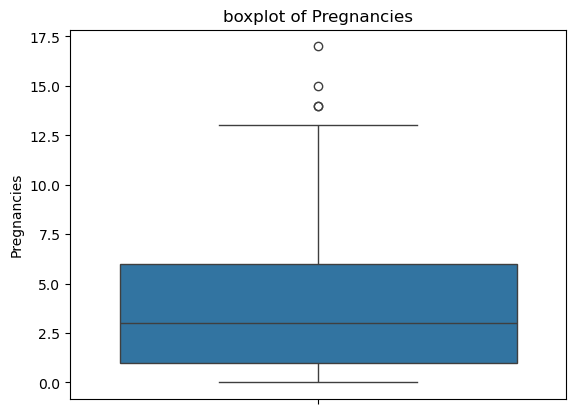

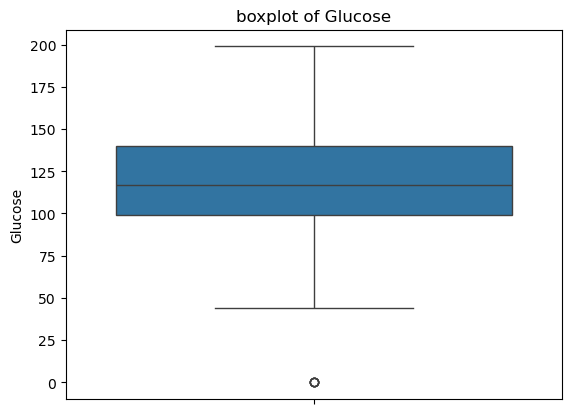

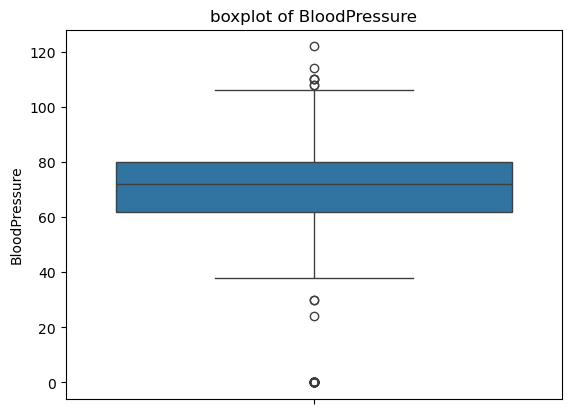

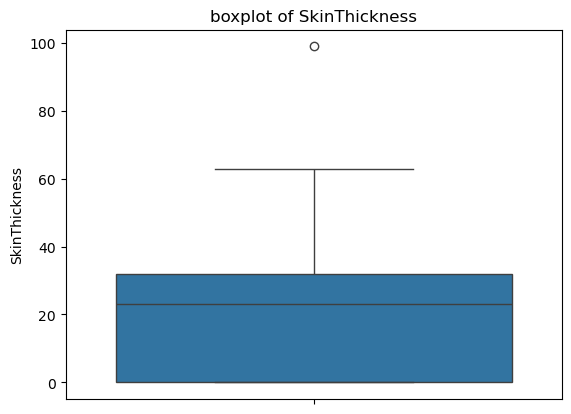

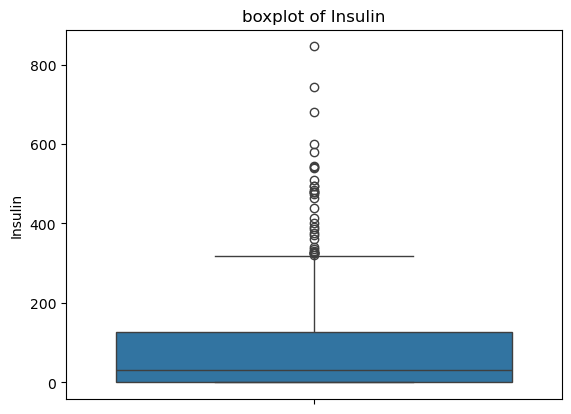

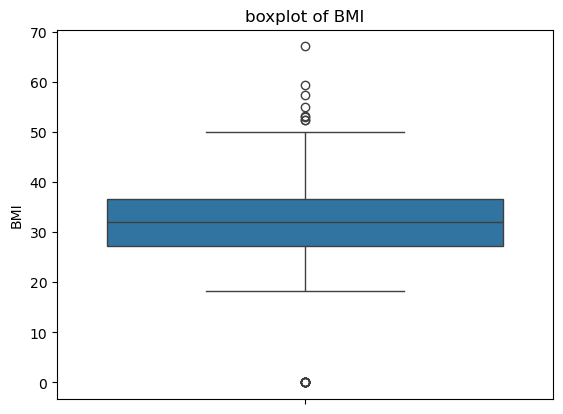

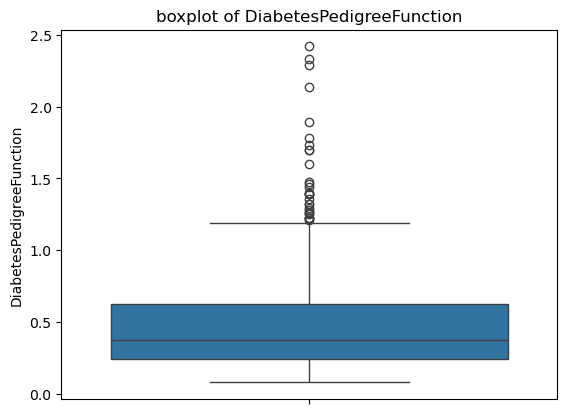

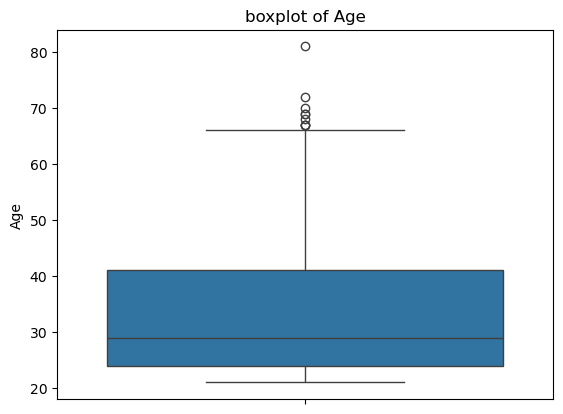

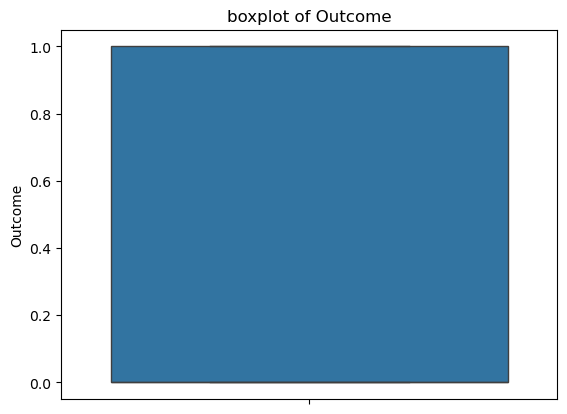

In [9]:
for cols in df.select_dtypes(include=['int','float']).columns:
    sns.boxplot(df[cols])
    plt.title(f"boxplot of {cols}")
    plt.show()

In [10]:
for i in df.select_dtypes(include=['int','float']).columns:

    q1=df[i].quantile(0.25)

    q3=df[i].quantile(0.75)

    IQR=q3-q1

    lower=q1-1.5*IQR

    upper=q3+1.5*IQR

    df[i]=df[i].clip(lower,upper)

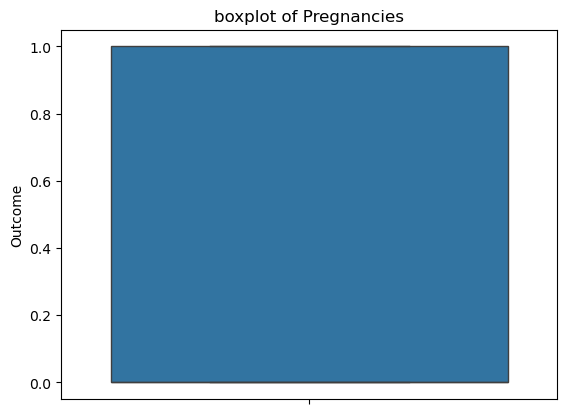

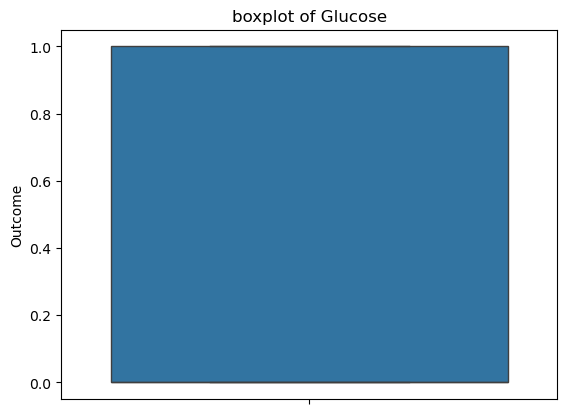

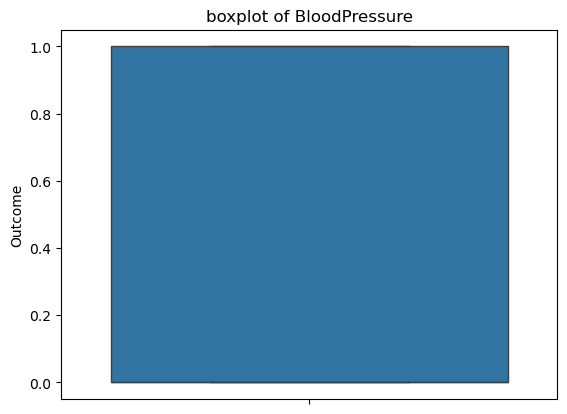

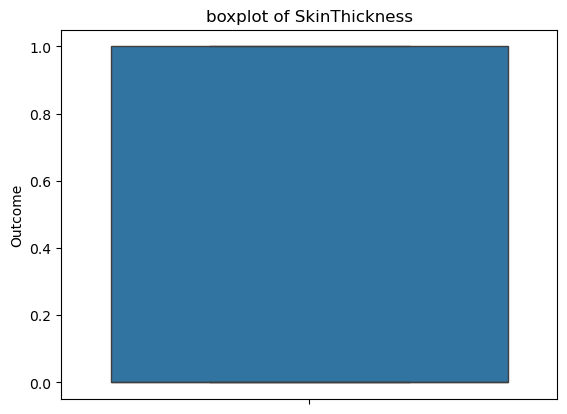

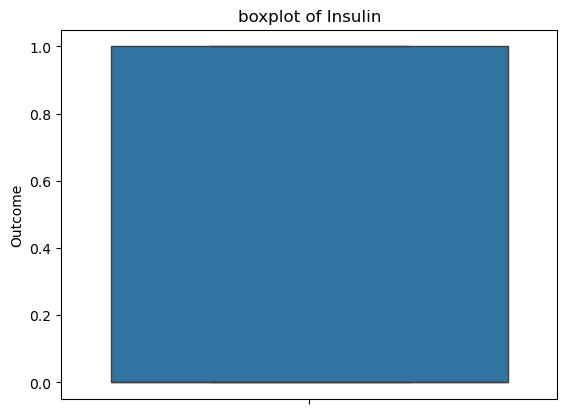

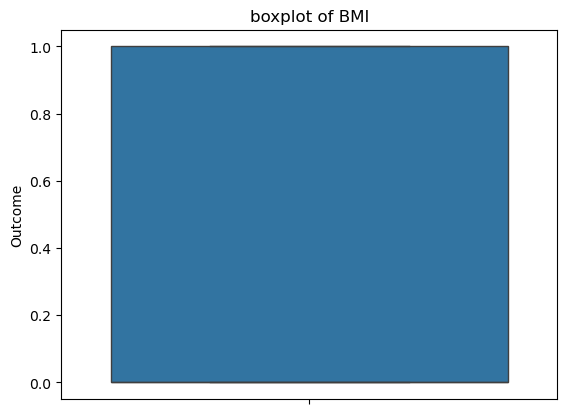

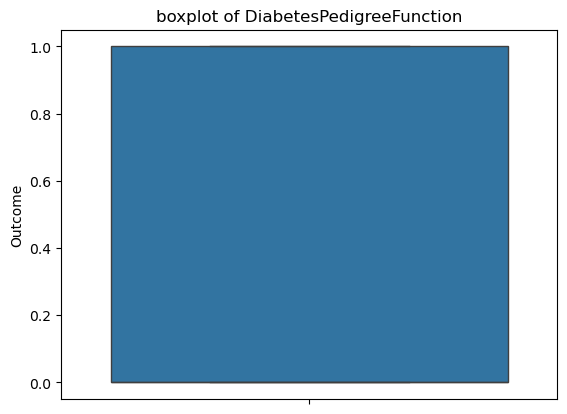

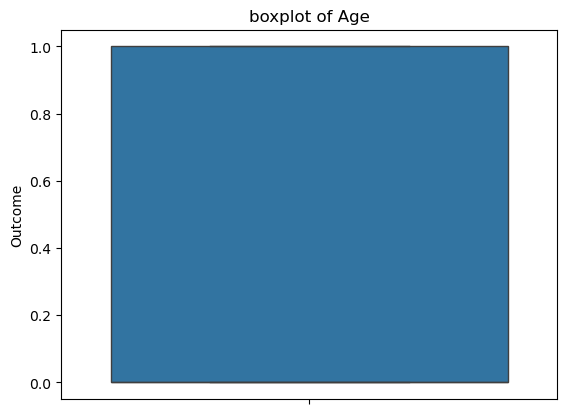

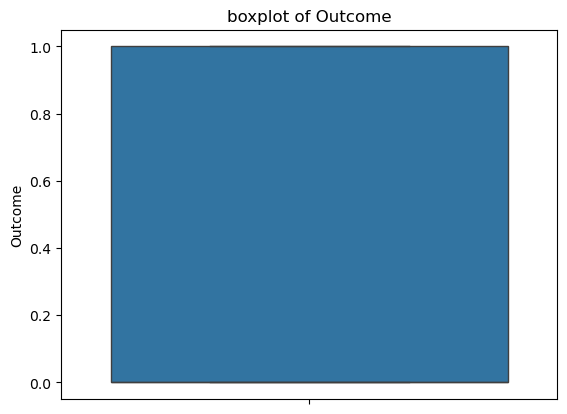

In [11]:
for cols in df.select_dtypes(include=['int','float']).columns:
    sns.boxplot(df[i])
    plt.title(f'boxplot of {cols}')
    plt.show()

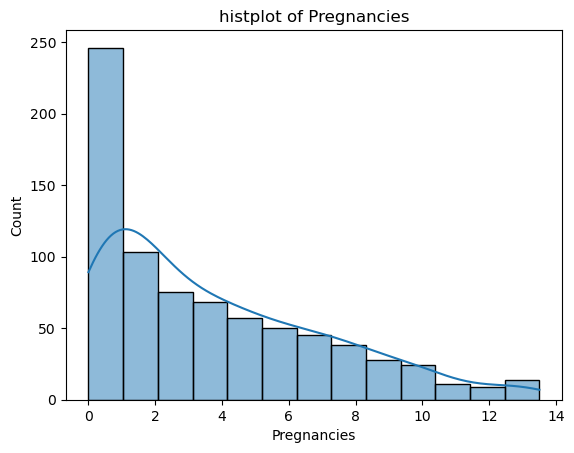

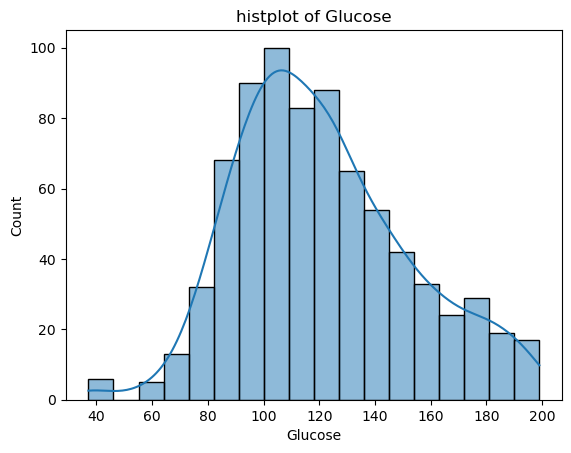

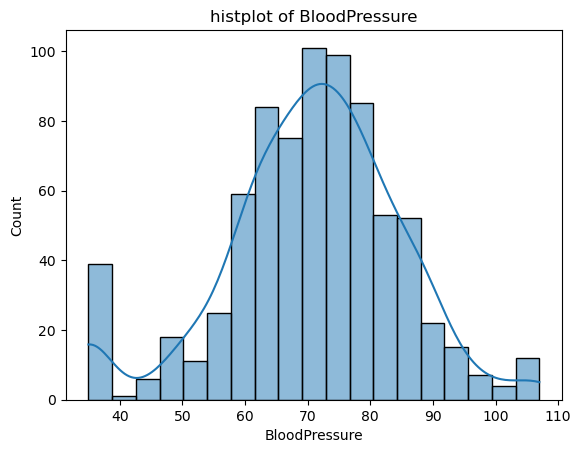

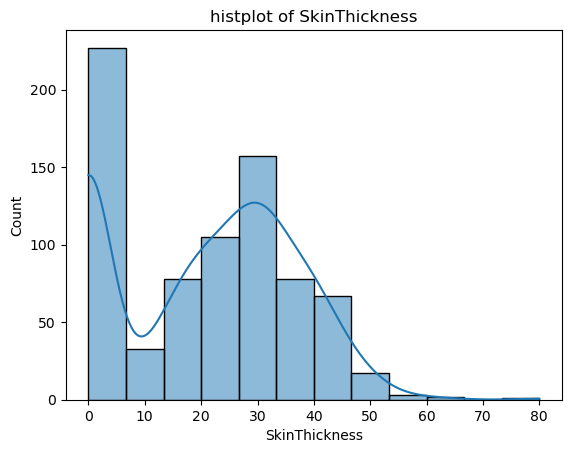

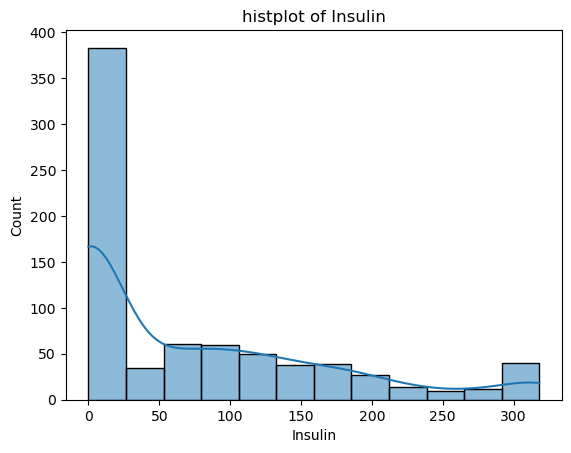

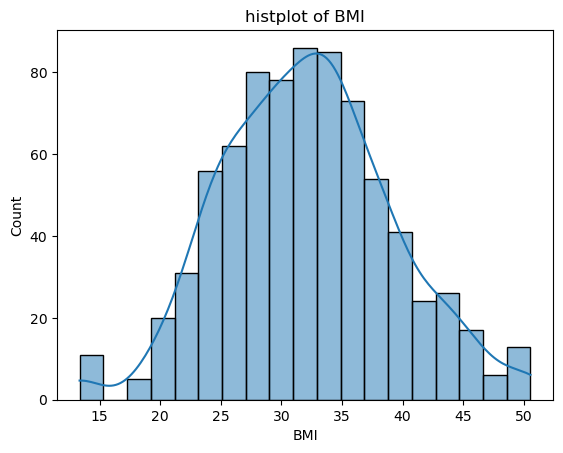

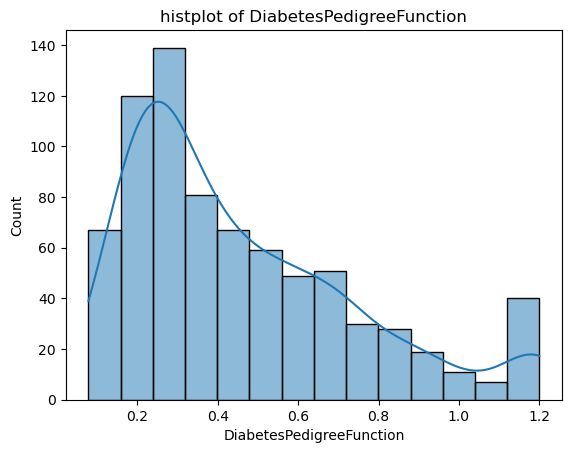

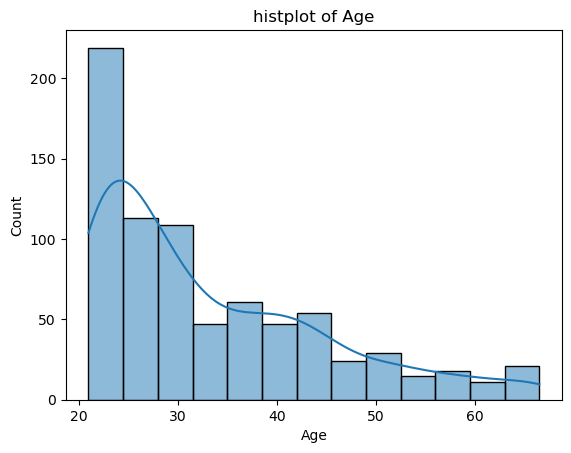

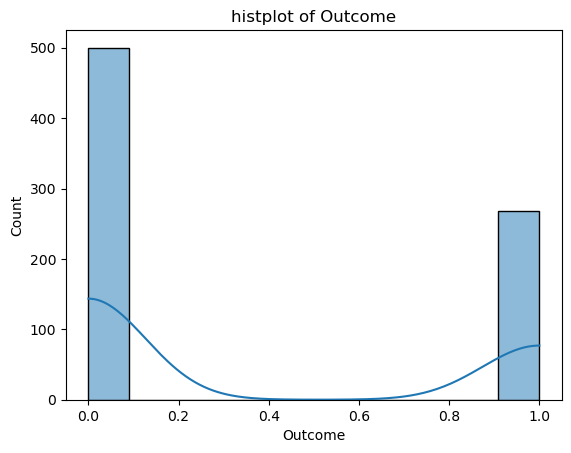

In [12]:
for cols in df.select_dtypes(include=['int','float']).columns:
    sns.histplot(data=df,x=cols,kde=True)
    plt.title(f'histplot of {cols}')
    plt.show()

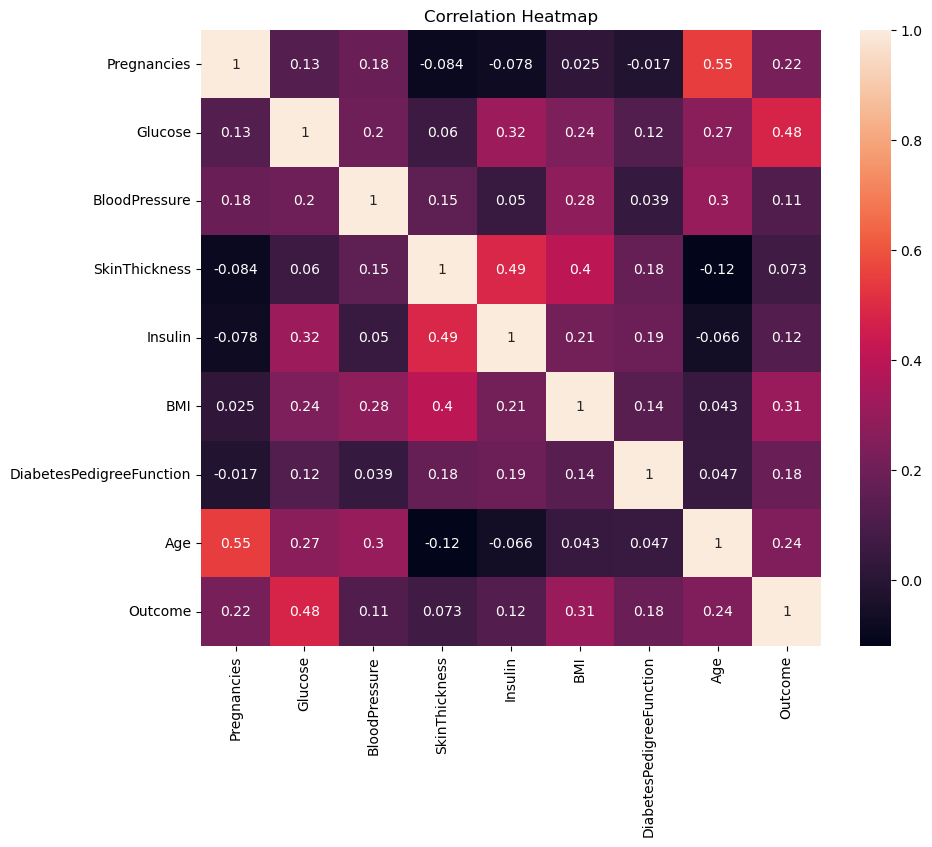

In [13]:
plt.figure(figsize=(10, 8))

sns.heatmap(df.corr(), annot=True)

plt.title("Correlation Heatmap")
plt.show()

In [14]:
x=df.drop(columns='Outcome')
y=df['Outcome']

In [15]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [20]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=40)

In [25]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(x_train,y_train)
pred=lr.predict(x_train)
pred
from sklearn.metrics import accuracy_score, classification_report


print(accuracy_score(y_train,pred))

print(classification_report(y_train,pred))

0.7833876221498371
              precision    recall  f1-score   support

           0       0.80      0.90      0.85       405
           1       0.74      0.56      0.64       209

    accuracy                           0.78       614
   macro avg       0.77      0.73      0.74       614
weighted avg       0.78      0.78      0.77       614



In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,roc_auc_score

lr = LogisticRegression()

lr.fit(x_train, y_train)

pred = lr.predict(x_test)

print("Accuracy:", accuracy_score(y_test, pred))

print(classification_report(y_test, pred))
print(roc_auc_score(y_test,pred))

Accuracy: 0.7727272727272727
              precision    recall  f1-score   support

           0       0.77      0.91      0.83        95
           1       0.79      0.56      0.65        59

    accuracy                           0.77       154
   macro avg       0.78      0.73      0.74       154
weighted avg       0.77      0.77      0.76       154

0.7322925958965208


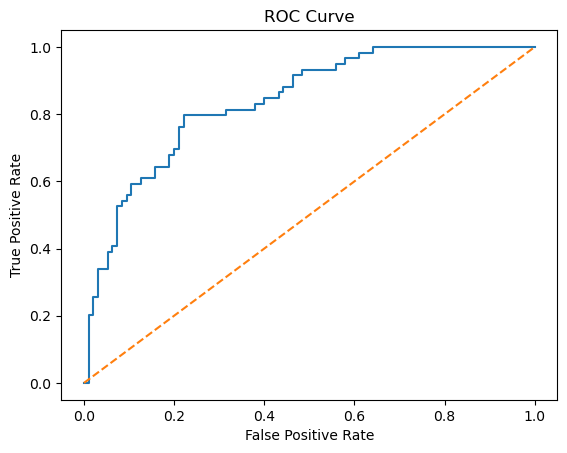

In [22]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

y_prob=lr.predict_proba(x_test)[:,1]

fpr,tpr,thresholds=roc_curve(y_test,y_prob)

plt.plot(fpr,tpr)

plt.plot([0,1],[0,1],linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.show()

In [23]:
for feature, coef in zip(x_train.columns, lr.coef_[0]):
    print(feature, ":", coef)

Pregnancies : 0.1901939385405885
Glucose : 0.03578515920106878
BloodPressure : -0.019613201016989094
SkinThickness : -0.0024155363298924747
Insulin : -0.0021300391284065196
BMI : 0.11005076252293838
DiabetesPedigreeFunction : 1.6465854576590508
Age : -0.00037749501585121004


In [24]:
import joblib
joblib.dump(lr,"rmodel.pkl")

['rmodel.pkl']